<a href="https://colab.research.google.com/github/tanu1304/data-science-projects/blob/main/Cross_Domain_Caricature__Recog_final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##Mounting drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


##Importing Libraries

In [ ]:
import os, torch
from torchvision import transforms as T             # For applying image transformation
from PIL import Image                               # For loading images
import matplotlib.pyplot as plt                     #For visualizing images and plots


# Selecting the device (GPU if available, else CPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(" Using device:", device)

#defining dataset paths
REAL_IMG_DIR = "/content/drive/MyDrive/CaVINet_Shared_final/aligned_real"        # Folder for real aligned face images
CARIC_IMG_DIR = "/content/drive/MyDrive/CaVINet_Shared_final/aligned_caricature" # Folder for caricature aligned images
EMBED_DIR = "/content/drive/MyDrive/CaVINet/final_outputs"

 Using device: cpu


In [ ]:
# Applying GAN-Like Augmentation
from torchvision.transforms import functional as TF
import torchvision.transforms as transforms
import random


# Defining a class to simulate GAN-like augmentations for caricature style distortion
class GANLikeCaricatureAug:
    def __init__(self):
        # Compose a series of aggressive style augmentations to mimic GAN-style exaggeration
        self.augment = transforms.Compose([
            transforms.RandomApply([
                transforms.ColorJitter(brightness=0.3, contrast=0.7, saturation=0.7, hue=0.1),    # Alters brightness, contrast, saturation, hue
                transforms.RandomPosterize(bits=4),                                                    # Reduces color depth (exaggerated color effects)
                transforms.RandomAdjustSharpness(sharpness_factor=2, p=0.7),                          #Enhances edges
                transforms.RandomPerspective(distortion_scale=0.4, p=0.5),                           #distorts image
                transforms.RandomRotation(degrees=10),                                               #Slight rotation to imitate exaggeration
            ], p=0.8),
            transforms.Resize((160, 160)),  # resizing to match FaceNet input size
            transforms.ToTensor(),          #Converting to tensor
        ])

    def __call__(self, img):
        return self.augment(img)

# Create an instance of the augmentation class
augmentor = GANLikeCaricatureAug()


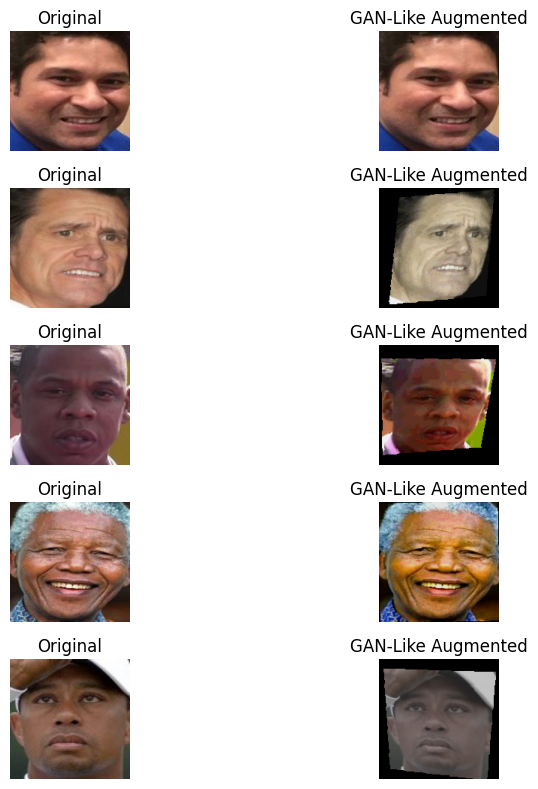

In [ ]:
#Visualizing GANlikeAugmentation Effect
# Pick 5 random real images and showing original vs augmented image
import random
real_person_dirs = sorted(os.listdir(REAL_IMG_DIR))
sample_imgs = []

for person in random.sample(real_person_dirs, 5):
    person_path = os.path.join(REAL_IMG_DIR, person)
    images = [f for f in os.listdir(person_path) if f.endswith(('.jpg', '.png'))]
    if images:
        img_path = os.path.join(person_path, random.choice(images))
        sample_imgs.append(img_path)

plt.figure(figsize=(10, 8))
for i, img_path in enumerate(sample_imgs):
    img = Image.open(img_path).convert('RGB')
    aug = augmentor(img)


    #Show original image
    plt.subplot(5, 2, 2*i+1)
    plt.imshow(img)
    plt.title("Original")
    plt.axis("off")

    #Show augmented image
    plt.subplot(5, 2, 2*i+2)
    plt.imshow(TF.to_pil_image(aug))                   # Convert Tensor back to PIL for plotting
    plt.title("GAN-Like Augmented")
    plt.axis("off")

plt.tight_layout()
plt.show()


In [ ]:
# Install facenet-pytorch
!pip install facenet-pytorch

# Importing modules
from facenet_pytorch import InceptionResnetV1
import torch


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.0/61.0 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 24.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.3/18.3 MB 67.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.5/4.5 MB 75.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 755.6/755.6 MB 1.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 410.6/410.6 MB 1.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.1/14.1 MB 77.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.7/23.7 MB 57.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 823.6/823.6 kB 32.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 731.7/731.7 MB 1.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 121.6/121.6 MB 7.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.5/56.5 MB 12.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 124.2

In [ ]:
!pip install tqdm
from tqdm import tqdm

In [ ]:
# Generate Augmented Embeddings
from facenet_pytorch import InceptionResnetV1
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
import torch

# Load pretrained FaceNet model
facenet = InceptionResnetV1(pretrained='vggface2').eval().to(device)               ########Do not run this code again .
# Custom Dataset class for real images with GAN-like augmentations applied
class RealAugmentedDataset(Dataset):
    def __init__(self, root_dir, id2label, transform):
        self.samples = []
        self.transform = transform
        self.id2label = id2label

        for name, lbl in id2label.items():
            person_dir = os.path.join(root_dir, name)
            if not os.path.isdir(person_dir): continue
            for f in os.listdir(person_dir):
                if f.lower().endswith(('jpg', 'jpeg', 'png')):
                    self.samples.append((os.path.join(person_dir, f), lbl))

    def __len__(self): return len(self.samples)

    def __getitem__(self, idx):
        img_path, label = self.samples[idx]
        img = Image.open(img_path).convert('RGB')
        aug_img = augmentor(img)  # Apply GAN-like augmentations
        return aug_img, label

# Create label map based on real identities
real_id2label = {name: i for i, name in enumerate(sorted(os.listdir(REAL_IMG_DIR)))}

# Create dataset and dataloader
aug_ds = RealAugmentedDataset(REAL_IMG_DIR, real_id2label, augmentor)
aug_dl = DataLoader(aug_ds, batch_size=64, shuffle=False, num_workers=2)

# Extract embeddings
aug_embeddings, aug_labels = [], []

with torch.no_grad():
    for xb, yb in tqdm(aug_dl, desc="Extracting embeddings"):
        xb = xb.to(device)
        emb = facenet(xb).cpu()
        aug_embeddings.append(emb)
        aug_labels.append(yb)

aug_embeddings = torch.cat(aug_embeddings)
aug_labels = torch.cat(aug_labels)

print("Augmented embeddings shape:", aug_embeddings.shape)
# Save embeddings for use in training
torch.save(aug_embeddings, "/content/drive/MyDrive/CaVINet/augmented_real_embeddings.pt")
torch.save(aug_labels,     "/content/drive/MyDrive/CaVINet/augmented_real_labels.pt")


##Loading all embeddings and labels

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
from tqdm import tqdm

# Load training data (real + augmented)
real_emb  = torch.load("/content/drive/MyDrive/CaVINet/final_outputs/real_embeddings.pt")
real_lbl  = torch.load("/content/drive/MyDrive/CaVINet/final_outputs/real_labels.pt")
aug_emb   = torch.load("/content/drive/MyDrive/CaVINet/augmented_real_embeddings.pt")
aug_lbl   = torch.load("/content/drive/MyDrive/CaVINet/augmented_real_labels.pt")

# Load test data (caricature)
car_emb   = torch.load("/content/drive/MyDrive/CaVINet/final_outputs/caricature_embeddings.pt")
car_lbl   = torch.load("/content/drive/MyDrive/CaVINet/final_outputs/caricature_labels.pt")


In [ ]:
# Combine real and augmented for training
train_X = torch.cat([real_emb, aug_emb])
train_y = torch.cat([real_lbl, aug_lbl])

print(" Train:", train_X.shape, "| Test:", car_emb.shape)

 Train: torch.Size([13100, 512]) | Test: torch.Size([4272, 512])


In [ ]:
# DataLoader
train_ds = TensorDataset(train_X, train_y)
train_dl = DataLoader(train_ds, batch_size=64, shuffle=True)

# Number of classes
num_classes = len(torch.unique(train_y))

In [ ]:
import torch.nn as nn

class EmbeddingClassifier(nn.Module):
    def __init__(self, emb_dim=512, num_classes=205):
        super().__init__()
        self.bn = nn.BatchNorm1d(emb_dim)                      # BatchNorm stabilizes training and helps with generalization
        self.fc = nn.Linear(emb_dim, num_classes)              # Final classifier layer: maps 512-dim embeddings to class scores

    def forward(self, x):
        x = self.bn(x)         # Apply normalization across embedding dimensions
        return self.fc(x)        # Output logits (pre-softmax)



In [ ]:
class CenterLoss(nn.Module):
    def __init__(self, num_classes=205, feat_dim=512):
        super().__init__()
        self.centers = nn.Parameter(torch.randn(num_classes, feat_dim))

    def forward(self, features, labels):
      # Get center vectors corresponding to each label in the batch
        batch_centers = self.centers[labels]

        # Compute squared Euclidean distance between features and their class centers
        return ((features - batch_centers)**2).sum(dim=1).mean()


##Training
###  Experimental Protocol

| **Component**    | **Description**                                            |
|------------------|------------------------------------------------------------|
| **Input**        | Precomputed real + GAN-augmented FaceNet embeddings (512-dim) |
| **Model**        | 1-layer Fully Connected (FC) classifier with BatchNorm     |
| **Losses**       | CrossEntropyLoss + 0.5 × CenterLoss                        |
| **Optimizer**    | Adam                                                       |
| **Learning Rate**| `1e-4`                                                     |
| **Epochs**       | 60                                                         |
| **Batch Size**   | 64                                                         |


Epoch 1, Loss: 257.4184
Epoch 2, Loss: 251.1911
Epoch 3, Loss: 246.0151
Epoch 4, Loss: 241.4989
Epoch 5, Loss: 237.3036
Epoch 6, Loss: 233.2430
Epoch 7, Loss: 229.3068
Epoch 8, Loss: 225.4500
Epoch 9, Loss: 221.6633
Epoch 10, Loss: 217.9462
Epoch 11, Loss: 214.2895
Epoch 12, Loss: 210.6893
Epoch 13, Loss: 207.1388
Epoch 14, Loss: 203.6546
Epoch 15, Loss: 200.2249
Epoch 16, Loss: 196.8555
Epoch 17, Loss: 193.5197
Epoch 18, Loss: 190.2407
Epoch 19, Loss: 187.0147
Epoch 20, Loss: 183.8408
Epoch 21, Loss: 180.7113
Epoch 22, Loss: 177.6171
Epoch 23, Loss: 174.5774
Epoch 24, Loss: 171.5840
Epoch 25, Loss: 168.6279
Epoch 26, Loss: 165.7272
Epoch 27, Loss: 162.8647
Epoch 28, Loss: 160.0422
Epoch 29, Loss: 157.2593
Epoch 30, Loss: 154.5249
Epoch 31, Loss: 151.8289
Epoch 32, Loss: 149.1680
Epoch 33, Loss: 146.5385
Epoch 34, Loss: 143.9590
Epoch 35, Loss: 141.4220
Epoch 36, Loss: 138.9161
Epoch 37, Loss: 136.4411
Epoch 38, Loss: 134.0289
Epoch 39, Loss: 131.6291
Epoch 40, Loss: 129.2764
Epoch 41,

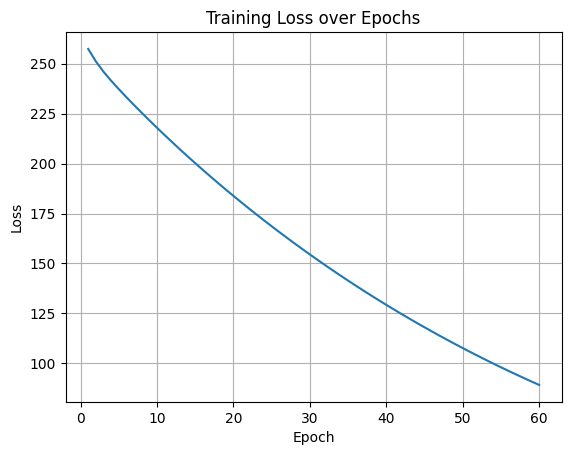

In [ ]:
# TRAINING LOOP (CrossEntropy + Center Loss)

import torch
from torch.utils.data import DataLoader, TensorDataset
import torch.nn.functional as F

# # Loading data
# # real_aug_embeddings: from real+augmented images
# # real_labels: correct labels
# train_ds = TensorDataset(real_emb, real_lbl)
# train_dl = DataLoader(train_ds, batch_size=64, shuffle=True)

model = EmbeddingClassifier().to(device)
center_loss = CenterLoss().to(device)

optimizer = torch.optim.Adam(list(model.parameters()) + list(center_loss.parameters()), lr=1e-4)
ce_loss = nn.CrossEntropyLoss()

alpha = 0.5  # weight for center loss
losses=[]
for epoch in range(1,61):
    model.train(); total_loss = 0
    for xb, yb in train_dl:
        xb, yb = xb.to(device), yb.to(device)
        logits = model(xb)                            # Get class scores from classifier
        loss_ce = ce_loss(logits, yb)                # Classification loss
        loss_center = center_loss(xb, yb)               # Center loss on embedding
        loss = loss_ce + alpha * loss_center           #Total combined loss

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()
    avg_loss = total_loss / len(train_dl)
    losses.append(avg_loss)
    print(f"Epoch {epoch}, Loss: {avg_loss:.4f}")

#Plot training loss curve
plt.plot(range(1,61), losses)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training Loss over Epochs")
plt.grid(True)
plt.show()

##Applying Flip TTA

In [ ]:
def get_normalized_embeddings(model, x, batch_size=64):
    model.eval()
    refined = []
    with torch.no_grad():
        for i in range(0, len(x), batch_size):
            xb = x[i:i+batch_size].to(device)
            out = F.normalize(model.bn(xb), dim=1)
            refined.append(out.cpu())
    return torch.cat(refined)

# real_refined = Refined embeddings of training set (real + augmented)
real_refined = get_normalized_embeddings(model, train_X)


In [ ]:
#class-wise mean embedding computation on real domain

# Determine total number of classes (max label + 1)
num_classes = train_y.max().item() + 1
means = []
for i in range(num_classes):
    idx = (train_y == i)
    mean_emb = F.normalize(train_X[idx].mean(dim=0), dim=0)        #compute mean embeddings  and normalize to unit vector
    means.append(mean_emb)
means = torch.stack(means)  # shape: [205, 512]
num_classes = train_y.max().item() + 1
refined_means = []



In [ ]:
from torchvision import transforms
from PIL import Image

transform_flip = transforms.Compose([
    transforms.Resize((160, 160)),
    transforms.RandomHorizontalFlip(p=1.0),  # Always flip
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5], std=[0.5])
])


In [ ]:
import os
import torch
class FlipCaricatureDataset(torch.utils.data.Dataset):
    def __init__(self, root_dir, label_map, transform):
        self.root_dir = root_dir
        self.transform = transform
        self.samples = []
        self.labels = []

        # Loop through each identity folder
        for class_name in sorted(os.listdir(root_dir)):
            class_path = os.path.join(root_dir, class_name)
            if not os.path.isdir(class_path):
                continue
        # Loop through each  image inside that identity
            for img_name in os.listdir(class_path):
                if img_name.lower().endswith(('jpg', 'png')):
                    self.samples.append(os.path.join(class_path, img_name))
                    self.labels.append(label_map[class_name])

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        img = Image.open(self.samples[idx]).convert('RGB')
        return self.transform(img), self.labels[idx]


In [ ]:
label_map = {name: i for i, name in enumerate(sorted(os.listdir(CARIC_IMG_DIR)))}
#Create dataset using the always-flipped transform
flip_caric_ds = FlipCaricatureDataset(CARIC_IMG_DIR, label_map, transform_flip)
# DataLoader for inference (no shuffling)
flip_caric_loader = torch.utils.data.DataLoader(flip_caric_ds, batch_size=64, shuffle=False)


In [ ]:
from facenet_pytorch import InceptionResnetV1

facenet = InceptionResnetV1(pretrained='vggface2').eval().to(device)


  0%|          | 0.00/107M [00:00<?, ?B/s]

In [ ]:
#FLIPPED CARICATURE EMBEDDING EXTRACTION
flip_embs = []
flip_labels = []

with torch.no_grad():
    for xb, yb in flip_caric_loader:
        xb = xb.to(device)
        feats = facenet(xb)                # Extract 512-dim embeddings from flipped caricatures
        flip_embs.append(feats.cpu())      # Move to CPU and store
        flip_labels.append(yb)                   # Store ground truth labels

# Combine all embeddings and labels
flip_embs = torch.cat(flip_embs)
flip_labels = torch.cat(flip_labels)

In [ ]:
torch.save(flip_embs,"/content/drive/MyDrive/CaVINet_Shared_final/flip_embs")
torch.save(flip_labels,"/content/drive/MyDrive/CaVINet_Shared_final/flip_labels")

In [ ]:
flip_embs=torch.load("/content/drive/MyDrive/CaVINet_Shared_final/flip_embs")
flip_labels=torch.load("/content/drive/MyDrive/CaVINet_Shared_final/flip_labels")

In [ ]:
# import torch.nn.functional as F
# avg_emb = F.normalize((car_emb + flip_embs) / 2, dim=1)
# Use trained BN layer to refine
caric_ref1 = model.bn(car_emb.to(device)).cpu()
caric_ref2 = model.bn(flip_embs.to(device)).cpu()

# Average the two (original + flipped)
avg_emb = F.normalize((caric_ref1 + caric_ref2) / 2, dim=1)


##COSINE SIMILARITY-BASED EVALUATION

In [ ]:
# Compute cosine similarity between each test embedding and all class mean embeddings
# avg_emb: [N_test, 512]
# means:   [N_classes, 512]

sim = F.cosine_similarity(avg_emb[:, None], means[None], dim=-1)
preds = sim.argmax(dim=1)
acc = (preds == car_lbl).float().mean().item()

print(f" Cosine Similarity Accuracy with Flip-TTA+bn: {acc*100:.2f}%")


 Cosine Similarity Accuracy with Flip-TTA+bn: 83.66%


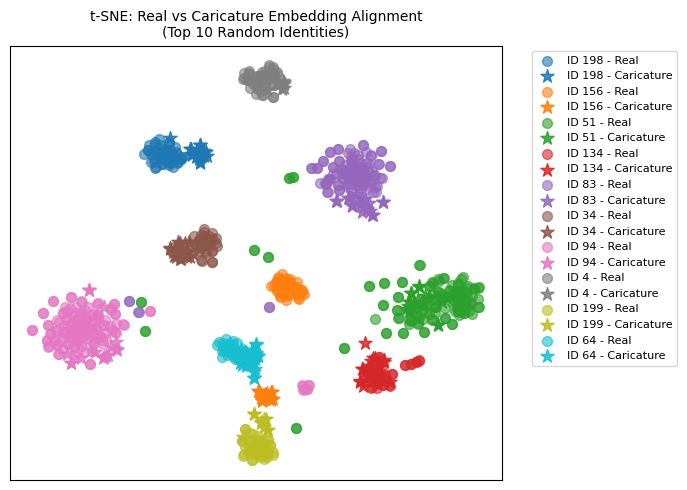

In [ ]:
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
import torch
import numpy as np
import random

# Select 10 random identities
unique_ids = torch.unique(train_y)  # training set has real + aug
selected_ids = random.sample(unique_ids.tolist(),10)

# Filter embeddings and labels for selected identities
real_sel, real_lbls = [], []
cari_sel, cari_lbls = [], []

for id_val in selected_ids:
    real_sel.append(real_refined[train_y == id_val])         # From training refined embeddings
    real_lbls.extend([id_val] * (train_y == id_val).sum().item())

    cari_sel.append(avg_emb[car_lbl == id_val])              # From test embeddings (flip-tta averaged)
    cari_lbls.extend([id_val] * (car_lbl == id_val).sum().item())

# Stack them
real_sel = torch.cat(real_sel)
cari_sel = torch.cat(cari_sel)

# Combine embeddings and labels
all_embs = torch.cat([real_sel, cari_sel])
all_lbls = real_lbls + cari_lbls
domains = ['Real'] * len(real_sel) + ['Caricature'] * len(cari_sel)

# Apply t-SNE
tsne = TSNE(n_components=2, perplexity=30, random_state=42)
emb_2d = tsne.fit_transform(all_embs.detach().numpy())



# Plot
plt.figure(figsize=(7, 5))
colors = plt.cm.tab10(np.linspace(0, 1, len(selected_ids)))

for i, id_val in enumerate(selected_ids):
    idx_real = [j for j, (lbl, d) in enumerate(zip(all_lbls, domains)) if lbl == id_val and d == 'Real']
    idx_cari = [j for j, (lbl, d) in enumerate(zip(all_lbls, domains)) if lbl == id_val and d == 'Caricature']

    plt.scatter(emb_2d[idx_real, 0], emb_2d[idx_real, 1],
                color=colors[i], marker='o', s=50, alpha=0.6, label=f'ID {id_val} - Real')

    plt.scatter(emb_2d[idx_cari, 0], emb_2d[idx_cari, 1],
                color=colors[i], marker='*', s=100, alpha=0.85, label=f'ID {id_val} - Caricature')

plt.title("t-SNE: Real vs Caricature Embedding Alignment\n(Top 10 Random Identities)", fontsize=10)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=8)
plt.xticks([])
plt.yticks([])
plt.box(True)

# Save the figure
plt.savefig("/content/drive/MyDrive/CaVINet_Shared_final/tsne_real_vs_caricature.png", dpi=300, bbox_inches='tight')
plt.tight_layout()
plt.show()


In [ ]:
from google.colab import files
files.download("/content/drive/MyDrive/CaVINet_Shared_final/tsne_real_vs_caricature.png")



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

##Testing on any outside caricature

In [ ]:
import os

# Make sure the identities are sorted like during training
label2name = {i: name for i, name in enumerate(sorted(os.listdir(REAL_IMG_DIR)))}

In [ ]:
print(label2name)

{0: 'aamir_khan', 1: 'abraham_lincoln', 2: 'adam_sandler', 3: 'adele', 4: 'adolf_hitler', 5: 'akhilesh_yadav', 6: 'albert_einstein', 7: 'alexandra_daddario', 8: 'amitabh_bachan', 9: 'angela_merkel', 10: 'angelina_jolie', 11: 'anna_hazare', 12: 'anne_hathway', 13: 'apj_abdul_kalam', 14: 'ar_rahman', 15: 'aravind_kejriwal', 16: 'arjen_robben', 17: 'arnold_schwarzenegger', 18: 'arturo_vidal', 19: 'arundhati_roy', 20: 'arvind_kejriwal', 21: 'barak_obama', 22: 'beckham', 23: 'beyonce', 24: 'bill_clinton', 25: 'bill_cosby', 26: 'bill_gates', 27: 'bill_murray', 28: 'brad_pitt', 29: 'bradley_cooper', 30: 'brazilian_ronaldo', 31: 'britney_spears', 32: 'bruce_willis', 33: 'bruno_mars', 34: 'cameron_diaz', 35: 'carlos_tevez', 36: 'charlie_sheen', 37: 'chris_gayle', 38: 'chuck_norris', 39: 'cristina_fernandez', 40: 'dalai_lama', 41: 'daniel_craig', 42: 'danny_devito', 43: 'david_villa', 44: 'dean_martin', 45: 'deepika_padukone', 46: 'del_piero', 47: 'denzel_washington', 48: 'dilma_rousseff', 49: '

In [ ]:
from torchvision import transforms
from PIL import Image
import torch.nn.functional as F

# Transformation
transform = transforms.Compose([
    transforms.Resize((160, 160)),
    transforms.ToTensor(),
    transforms.Normalize([0.5], [0.5])
])

def predict_identity_facenet(image_path, facenet, class_means, label2name, device):
    img = Image.open(image_path).convert('RGB')
    img_tensor = transform(img).unsqueeze(0).to(device)

    # Flip horizontally
    flipped = torch.flip(img_tensor, dims=[3])

    # Get embeddings
    with torch.no_grad():
        emb1 = facenet(img_tensor)
        emb2 = facenet(flipped)

    # Average both embeddings
    test_emb = (emb1 + emb2) / 2
    test_emb = F.normalize(test_emb, dim=1)

    # Compare with class means
    similarity = F.cosine_similarity(test_emb, class_means)
    pred_idx = similarity.argmax().item()
    pred_name = label2name[pred_idx]

    return pred_idx, pred_name


In [ ]:
image_path = "/content/drive/MyDrive/Caricature_Only_Dataset/Bill_gates/Bill_gates_148_caricature.jpg"

pred_idx, pred_name = predict_identity_facenet(image_path, facenet, means, label2name, device=device)

print(f"Predicted Identity Index: {pred_idx}")
print(f" Predicted Identity Name : {pred_name}")



Predicted Identity Index: 26
 Predicted Identity Name : bill_gates


##Testing entire caricature folder

In [ ]:
name2label = {v: k for k, v in label2name.items()}

In [ ]:
import os
from PIL import Image
from torchvision import transforms
import torch.nn.functional as F

transform = transforms.Compose([
    transforms.Resize((160, 160)),
    transforms.ToTensor(),
    transforms.Normalize([0.5], [0.5])
])

def predict_identity_from_folder(folder_path, true_name, facenet, means, label2name, device='cpu'):
    true_label = name2label[true_name]
    total, correct = 0, 0

    for file in os.listdir(folder_path):
        if file.lower().endswith(('.jpg', '.jpeg', '.png')):
            image_path = os.path.join(folder_path, file)
            img = Image.open(image_path).convert('RGB')
            img_tensor = transform(img).unsqueeze(0).to(device)
            flipped = torch.flip(img_tensor, dims=[3])

            with torch.no_grad():
                emb1 = facenet(img_tensor)
                emb2 = facenet(flipped)

            emb = F.normalize((emb1 + emb2) / 2, dim=1)
            sim = F.cosine_similarity(emb, means)
            pred_idx = sim.argmax().item()
            pred_name = label2name[pred_idx]

            total += 1
            if pred_idx == true_label:
                correct += 1
            print(f" {file} ->Predicted: {pred_name} " if pred_idx == true_label else f" {file} -> Predicted: {pred_name} ")

    acc = (correct / total) * 100 if total > 0 else 0.0
    print(f"\n Accuracy for folder '{true_name}': {correct}/{total} = {acc:.2f}%")
folder_path = "/content/drive/MyDrive/Caricature_Only_Dataset/Bill_gates"
true_identity_name = "bill_gates"  #  match folder name in training identities

predict_identity_from_folder(folder_path, true_identity_name, facenet, means, label2name, device=device)


 Bill_gates_63_caricature.jpg -> Predicted: dalai_lama 
 Bill_gates_28_caricature.jpg -> Predicted: ed_harris 
 Bill_gates_32_caricature.jpg ->Predicted: bill_gates 
 Bill_gates_22_caricature.jpg ->Predicted: bill_gates 
 Bill_gates_52_caricature.jpg -> Predicted: lk_advani 
 Bill_gates_72_caricature.jpg ->Predicted: bill_gates 
 Bill_gates_56_caricature.jpg ->Predicted: bill_gates 
 Bill_gates_51_caricature.jpg -> Predicted: lk_advani 
 Bill_gates_58_caricature.jpg ->Predicted: bill_gates 
 Bill_gates_62_caricature.jpg -> Predicted: dalai_lama 
 Bill_gates_35_caricature.jpg ->Predicted: bill_gates 
 Bill_gates_26_caricature.jpg -> Predicted: eminem 
 Bill_gates_06_caricature.jpg ->Predicted: bill_gates 
 Bill_gates_42_caricature.jpg ->Predicted: bill_gates 
 Bill_gates_71_caricature.jpg -> Predicted: shahrukh_khan 
 Bill_gates_74_caricature.jpg -> Predicted: jay-z 
 Bill_gates_43_caricature.jpg -> Predicted: manmohan_singh 
 Bill_gates_07_caricature.jpg ->Predicted: bill_gates 
 Bill_

In [ ]:
#Counting missclassified identitites and correct one
# - `preds` : predicted labels (from cosine similarity or classifier)
# - `car_lbl` : true labels of caricature images (size [N])

correct = (preds == car_lbl).sum().item()
total = len(car_lbl)
incorrect = total - correct
accuracy = correct / total * 100

print(f"Correctly Classified : {correct}")
print(f" Misclassified       : {incorrect}")
print(f"Overall Top-1 Accuracy : {accuracy:.2f}%")


Correctly Classified : 3574
 Misclassified       : 698
Overall Top-1 Accuracy : 83.66%


<Figure size 4000x500 with 0 Axes>

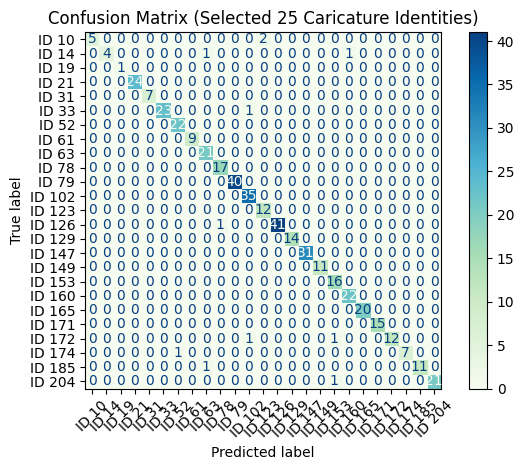

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Filter only the selected identities
selected_set = random.sample(torch.unique(car_lbl).tolist(), 25)

# Create filtered true & predicted label lists
filtered_true = []
filtered_pred = []

for t, p in zip(car_lbl, preds):
    if t.item() in selected_set:
        filtered_true.append(t.item())
        filtered_pred.append(p.item())

# Sort labels for display order
filtered_labels = sorted(selected_set)

# Compute confusion matrix
cm = confusion_matrix(filtered_true, filtered_pred, labels=filtered_labels)

# Display the matrix
plt.figure(figsize=(40, 5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[f"ID {i}" for i in filtered_labels])
disp.plot(cmap="GnBu", xticks_rotation=45, colorbar=True)
plt.title("Confusion Matrix (Selected 25 Caricature Identities)")
plt.tight_layout()
plt.show()


In [ ]:
import pandas as pd

cm_all = confusion_matrix(car_lbl, preds, labels=list(label2name.keys()))
df_cm = pd.DataFrame(cm_all, index=[label2name[i] for i in label2name],
                              columns=[label2name[i] for i in label2name])

df_cm.to_csv("/content/drive/MyDrive/CaVINet_Shared_final/full_confusion_matrix.csv")  #Full Confusion matrix saved as csv


In [ ]:

# Get top 3 predicted class indices
top3_preds = torch.topk(sim, k=3, dim=1).indices

# Check if true label is in top 3
top3_correct = torch.tensor([
    true_lbl in top3 for true_lbl, top3 in zip(car_lbl, top3_preds)
])

top3_acc = top3_correct.float().mean().item()
print(f"Top-3 Accuracy: {top3_acc * 100:.2f}%")


Top-3 Accuracy: 91.92%


In [ ]:

# Get top 5 predicted class indices
top5_preds = torch.topk(sim, k=5, dim=1).indices

# Check if true label is in top 5
top5_correct = torch.tensor([
    true_lbl in top5 for true_lbl, top5 in zip(car_lbl, top5_preds)
])

top5_acc = top5_correct.float().mean().item()
print(f"Top-5 Accuracy: {top5_acc * 100:.2f}%")

Top-5 Accuracy: 94.66%


##Classification Report

In [ ]:
from sklearn.metrics import classification_report

# preds = predicted labels (tensor)
# car_lbl = true labels (tensor)

report = classification_report(car_lbl, preds, target_names=[label2name[i] for i in range(len(label2name))])
print(report)


                        precision    recall  f1-score   support

            aamir_khan       0.91      0.67      0.77        15
       abraham_lincoln       0.96      1.00      0.98        25
          adam_sandler       1.00      0.43      0.61        23
                 adele       0.70      0.95      0.81        20
          adolf_hitler       0.80      1.00      0.89         8
        akhilesh_yadav       1.00      0.75      0.86        16
       albert_einstein       0.80      0.94      0.86        17
    alexandra_daddario       0.71      0.71      0.71         7
        amitabh_bachan       0.37      1.00      0.54         7
         angela_merkel       0.81      0.96      0.88        23
        angelina_jolie       0.71      0.21      0.32        24
           anna_hazare       0.62      1.00      0.77        10
          anne_hathway       0.87      0.76      0.81        17
       apj_abdul_kalam       0.88      0.70      0.78        10
             ar_rahman       0.50      

##Saving all important parameters

In [ ]:
import torch
import os
import pickle

# Set save path
SAVE_PATH = "/content/drive/MyDrive/CaVINet_Shared_final"
os.makedirs(SAVE_PATH, exist_ok=True)


# Save Trained Classifier Model

torch.save(model.state_dict(), f"{SAVE_PATH}/embedding_classifier_centerloss.pth")

#  Save Center Loss Parameters

torch.save(center_loss.state_dict(), f"{SAVE_PATH}/center_loss_centers.pth")

# Save Mean Embeddings and Refined Embeddings

torch.save(means, f"{SAVE_PATH}/class_means.pt")                     # Class-wise mean embeddings
torch.save(real_refined, f"{SAVE_PATH}/real_refined_embeddings.pt") # Refined embeddings for real+aug


# Save Caricature Predictions  and Labels

torch.save(preds, f"{SAVE_PATH}/caricature_predictions.pt")
torch.save(car_lbl, f"{SAVE_PATH}/caricature_labels.pt")

# Save Flip-Averaged Caricature Embeddings

torch.save(avg_emb, f"{SAVE_PATH}/flip_tta_avg_embeddings.pt")


# Save Top-3 and Top-5 Predictions

torch.save(top3_preds, f"{SAVE_PATH}/top3_predictions.pt")
torch.save(top5_preds, f"{SAVE_PATH}/top5_predictions.pt")


#Save Label Mappings

with open(f"{SAVE_PATH}/label2name.pkl", "wb") as f:
    pickle.dump(label2name, f)

with open(f"{SAVE_PATH}/name2label.pkl", "wb") as f:
    pickle.dump(name2label, f)


#Save Classification Report

from sklearn.metrics import classification_report

report_txt = classification_report(car_lbl, preds, target_names=[label2name[i] for i in range(len(label2name))])
with open(f"{SAVE_PATH}/classification_report.txt", "w") as f:
    f.write(report_txt)


# Save Summary File

with open(f"{SAVE_PATH}/final_results_summary.txt", "w") as f:
    f.write(f"Top-1 Accuracy : {acc*100:.2f}%\n")
    f.write(f"Top-3 Accuracy : {top3_acc*100:.2f}%\n")
    f.write(f"Top-5 Accuracy : {top5_acc*100:.2f}%\n")
    f.write(f"Correctly Classified : {correct}\n")
    f.write(f"Misclassified         : {incorrect}\n")

print(" All training artifacts saved successfully.")




 All training artifacts saved successfully.


In [ ]:

# Device setup
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Paths
SAVE_PATH = "/content/drive/MyDrive/CaVINet_Shared_final"

# Rebuild the model architecture

model = EmbeddingClassifier(emb_dim=512, num_classes=205).to(device)
model.load_state_dict(torch.load(f"{SAVE_PATH}/embedding_classifier_centerloss.pth", map_location=device))
model.eval()

# Load Center Loss if needed (for analysis or retraining)
center_loss = CenterLoss(num_classes=205, feat_dim=512).to(device)
center_loss.load_state_dict(torch.load(f"{SAVE_PATH}/center_loss_centers.pth", map_location=device))

#Load other components
means = torch.load(f"{SAVE_PATH}/class_means.pt", map_location=device)
real_refined = torch.load(f"{SAVE_PATH}/real_refined_embeddings.pt", map_location=device)
preds = torch.load(f"{SAVE_PATH}/caricature_predictions.pt", map_location=device)

#Load label-name mappings
with open(f"{SAVE_PATH}/label2name.pkl", "rb") as f:
    label2name = pickle.load(f)

with open(f"{SAVE_PATH}/name2label.pkl", "rb") as f:
    name2label = pickle.load(f)

print("Model and all components successfully loaded.")

Model and all components successfully loaded.
